# Day 6 lecture: Business intelligence strategy, case studies and ethics

<p class="lead">
Dashboards, forecasts and simulations only create value when they change decisions, and they can do harm when they are built on the wrong data or the wrong incentives. This lecture shows how an organisation plans business intelligence (BI) as a strategy, how BI tools fit together, how to judge whether a BI project worked, and how to weigh privacy, bias, transparency and the misuse of metrics. It ends with the briefing for Assignment 3.
</p>

Open this notebook in JupyterLab from the course folder (next to the `data` folder) and run each cell from top to bottom with **Shift + Enter**.

---

## Recap quiz

Before we start, answer the closing quiz at the end of yesterday's lecture on [financial modelling and simulation](D5_lecture_financial_modelling_simulation.md). Write short answers; we discuss them together.

---

## What you will be able to do

1. Explain what business intelligence is and how it differs from a single analysis.
2. Describe the elements of a **BI strategy** and place an organisation on a **maturity** ladder.
3. Sketch a **BI architecture**, from data sources to decisions, and say which tool (Excel, Python, Tableau) does which job.
4. Explain why a **single, written metric definition** matters, and show how two "reasonable" definitions give different answers.
5. Evaluate a **BI case**: decision, users, data, tools, evidence of impact and risks, including whether the evidence of impact is convincing.
6. Recognise and reduce four ethical risks: **privacy**, **bias**, **lack of transparency** and **misuse of metrics**; place a decision in its **societal context**.
7. Put an ethical choice into the numbers, so that a board can weigh it knowingly.

**Reading:** Tableau (n.d.), *Developing a business intelligence strategy*; ThoughtSpot (n.d.), *How to develop a successful business intelligence strategy*.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. **Check your understanding** boxes are short questions to answer in your own words, alone or with the person next to you.

| Part | Topic |
|---|---|
| 1 | What business intelligence is |
| 2 | BI strategy |
| 3 | BI tools and architecture |
| 4 | BI case studies: judging impact |
| 5 | Ethics: privacy, bias, transparency, misuse of metrics |
| 6 | Societal context: putting ethics into the numbers |
| 7 | Assignment 3 briefing |

The setup cell loads the libraries and the bundled restaurant **tips** data (244 bills from one restaurant, recorded by a waiter; from Bryant and Smith, 1995), which several demonstrations use.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"   # context
INK = "#55534e"    # notes and labels
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
pd.set_option("display.width", 120)

tips = pd.read_csv("data/tips.csv")
print(f"tips: {len(tips)} bills x {tips.shape[1]} columns")
print(tips.head(3).to_string())

tips: 244 bills x 7 columns
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3


---

## Part 1: What business intelligence is

**Business intelligence (BI)** is the set of people, processes and tools that turns an organisation's data into information that people use, **repeatedly**, to make decisions. An analysis answers one question once. BI answers recurring questions every day, week or month, for many users, from data everyone trusts.

| | A one-off analysis | Business intelligence |
|---|---|---|
| **Question** | "Why did returns rise in March?" | "How are returns this week, by region, against target?" |
| **Users** | One manager | Many people, at several levels |
| **Data** | A file prepared once | Data refreshed automatically from the source systems |
| **Output** | A report or a notebook | Dashboards, scheduled reports, alerts, self-service exploration |
| **Success** | The question is answered | Decisions are made faster and better, again and again |

### The decision loop

BI is worth its cost only if it closes a loop:

1. **Data** is captured by operational systems (tills, websites, sensors, HR and finance systems).
2. It becomes **information**: cleaned, joined, summarised into KPIs.
3. A person draws an **insight**: "stock-outs are rising in the north".
4. They make a **decision** and take **action**: "re-order earlier for those stores".
5. The result is **measured** with the same data, and the loop starts again.

Most failed BI projects break the loop at step 3 or 4: the dashboards exist, but nobody's decisions change.

### BI across the kinds of analytics

The course has used all four kinds of analytics. BI platforms began with the first two and now reach into the last two.

| Kind | Question | BI example from this course |
|---|---|---|
| **Descriptive** | What happened? | The Tableau dashboard of Lab 2 |
| **Diagnostic** | Why? | Drilling down by region or product |
| **Predictive** | What will happen? | Excel's Forecast Sheet (Lab 7 this afternoon) |
| **Prescriptive** | What should we do? | A simulation that compares strategies (Lab 6, Assignment 3) |

> **Check your understanding**
>
> A sales director receives a PDF report every Monday, reads it, and files it. Where is the decision loop broken, and what one change would you suggest?

---

## Part 2: BI strategy

A **BI strategy** is the plan that links BI work to the organisation's goals: which decisions to improve, for whom, with which data and tools, and how to tell whether it worked. Without one, organisations collect tools and dashboards that nobody uses.

### Six elements of a BI strategy

| Element | Questions to answer | A warning sign |
|---|---|---|
| **Business goals** | Which decisions will BI improve? How will we measure the improvement? | "We need a dashboard" with no decision named |
| **People** | Who uses it? What skills and training do they need? Who **owns** each KPI? | One analyst everyone depends on |
| **Process** | How do insights reach decisions: meetings, alerts, approvals? | Dashboards nobody opens before the meeting |
| **Data and governance** | Is there one source of truth? Written definitions? Quality checks? Access rights and privacy? | Two departments report different revenue |
| **Technology** | Which tools for which job, and how do they connect? | Every team buys its own tool |
| **Value and adoption** | Is BI used? Did decisions or KPIs improve? | Success measured by the number of dashboards |

### A roadmap in six steps

1. **Start from decisions.** List the 5–10 recurring decisions that matter most (pricing, stock, staffing, credit…).
2. **Name the people.** For each decision: who decides, how often, with what information today.
3. **Define the KPIs** that serve those decisions, and write a definition for each (Part 3).
4. **Audit the data.** Where does each KPI's data live? Is it complete, timely and allowed to be used?
5. **Pilot** with one team and one decision; measure the effect against a comparison (Part 4).
6. **Scale** what worked; retire what is not used.

### Maturity: where is the organisation now?

| Level | Typical state | Next step |
|---|---|---|
| 1 Ad hoc | Spreadsheets e-mailed around; each person has "their" numbers | Agree definitions for a few key KPIs |
| 2 Reporting | Standard reports from one system, produced by hand | Automate the data refresh |
| 3 Managed | A governed data store and shared dashboards; one source of truth | Self-service for trained users |
| 4 Predictive | Forecasts and models alongside the dashboards | Measure forecast error; act on predictions |
| 5 Optimised | Simulations and recommendations built into processes | Keep checking impact, fairness and side effects |

Organisations rarely jump levels. A forecasting tool (level 4) built on data nobody agrees on (level 1) produces confident, wrong numbers.

### Measuring the BI programme itself

| KPI for BI | What it shows |
|---|---|
| Active users per week | Adoption: are people using it? |
| Time from question to answer | Speed: has self-service helped? |
| Data-quality incidents per month | Trust: are the numbers reliable? |
| Decisions or processes that changed | Value: the only measure that really counts |

> **Check your understanding**
>
> A hospital has bought a modern BI platform and built 120 dashboards in a year, but ward managers still plan staff rosters from their own spreadsheets. Which **two** elements of the strategy would you examine first, and what level of maturity is the hospital really at?

---

## Part 3: BI tools and architecture

A BI system is a chain of layers. Each layer has one job; problems in an early layer show up as wrong numbers in the last.

| Layer | Job | Examples |
|---|---|---|
| **1 Sources** | Record what happens | Point-of-sale tills, website logs, ERP and HR systems, sensors, surveys, spreadsheets |
| **2 Integration (ETL)** | **E**xtract the data, **T**ransform it (clean, join, check), **L**oad it into storage, on a schedule | SQL scripts, Python, data-pipeline tools |
| **3 Storage** | Keep history in one place, organised for analysis | A **data warehouse** (tidy tables) or a **data lake** (raw files) |
| **4 Semantic / metric layer** | Define each business term and KPI **once**: "revenue", "active customer", "tip rate" | A metrics catalogue; Tableau data sources; a documented Excel model |
| **5 Analysis and presentation** | Explore, model, show | **Excel** (models, what-if, simulation), **Python** (cleaning, text mining, regression), **Tableau** (interactive dashboards) |
| **6 Decisions and action** | Use the result | Meetings, alerts, automated re-ordering |

### Which tool for which job (this course)

| Tool | Strengths | Weaknesses |
|---|---|---|
| **Excel** | Everyone has it; transparent formulas; what-if analysis, Data Tables, simulation, Forecast Sheet | Easy to break; hard to audit large models; manual refresh; version chaos by e-mail |
| **Python (Jupyter)** | Repeatable, large data, text mining, statistics and machine learning; every step is written down | Needs programming skills; not a dashboard tool for managers |
| **Tableau** | Fast interactive dashboards; drag-and-drop; sharing and filtering | Needs clean, well-shaped data; calculations can hide definitions |

In practice they work together: Python or a pipeline prepares the data, Excel models a decision, Tableau shows the result to many users. Assignment 3 uses exactly this chain: Excel simulates, Tableau visualises, your report recommends.

### Governed and self-service BI

**Governed** BI means central teams publish certified data sources and KPIs. **Self-service** BI lets business users build their own views. Good strategies combine them: certified data and definitions in the middle, freedom to explore at the edges. Self-service without governance leads to "two versions of the truth".

### Why one written definition matters

Here is the problem in miniature. A manager asks the restaurant's two analysts for "the tip rate" and "the average spend per person". Both analysts are careful; they just choose different, reasonable definitions.

> **Predict, then reveal**
>
> Will the two analysts' numbers differ by a little, by a lot, or not at all?

In [2]:
# Analyst 1: compute the measure for each bill, then average the bills ("mean of ratios")
tip_rate_1 = (tips["tip"] / tips["total_bill"]).mean()
spend_pp_1 = (tips["total_bill"] / tips["size"]).mean()

# Analyst 2: add up first, then divide ("ratio of totals")
tip_rate_2 = tips["tip"].sum() / tips["total_bill"].sum()
spend_pp_2 = tips["total_bill"].sum() / tips["size"].sum()

answers = pd.DataFrame({
    "Analyst 1: average of each bill's value": [f"{tip_rate_1:.1%}", f"{spend_pp_1:.2f}"],
    "Analyst 2: total ÷ total": [f"{tip_rate_2:.1%}", f"{spend_pp_2:.2f}"],
}, index=["Tip rate", "Spend per person (US dollars)"])
print(answers.to_string())

                              Analyst 1: average of each bill's value Analyst 2: total ÷ total
Tip rate                                                        16.1%                    15.2%
Spend per person (US dollars)                                    7.89                     7.70


Both answers above are "correct": they answer different questions. Analyst 1 gives every **bill** equal weight, so a small bill with a generous tip counts as much as a large party's bill. Analyst 2 gives every **dollar** (or every diner) equal weight. If one dashboard shows the first number and another the second, managers argue about the data instead of the decision.

The cure is a **metric contract**: one written definition per KPI, stored in the semantic layer and used by every tool. The next cell writes three definitions as a small catalogue and computes every KPI, for any grouping, from that single place.

In [3]:
# A tiny "semantic layer": each KPI is defined once, as a function of a table of bills
METRICS = {
    "bills": {
        "definition": "Number of bills (one row = one bill)",
        "compute": lambda d: len(d),
    },
    "tip_rate": {
        "definition": "Total tips ÷ total bill amount (ratio of totals)",
        "compute": lambda d: d["tip"].sum() / d["total_bill"].sum(),
    },
    "spend_per_person": {
        "definition": "Total bill amount ÷ total diners, US dollars (ratio of totals)",
        "compute": lambda d: d["total_bill"].sum() / d["size"].sum(),
    },
}


def kpi_table(data, by):
    """Every KPI in the catalogue, for each group in `by`, from the one shared definition."""
    rows = {name: data.groupby(by).apply(m["compute"], include_groups=False) for name, m in METRICS.items()}
    return pd.DataFrame(rows)


for name, m in METRICS.items():
    print(f"{name:<17} {m['definition']}")
print()
print(kpi_table(tips, "day").reindex(["Thur", "Fri", "Sat", "Sun"]).to_string(
    formatters={"tip_rate": "{:.1%}".format, "spend_per_person": "{:.2f}".format}))

bills             Number of bills (one row = one bill)
tip_rate          Total tips ÷ total bill amount (ratio of totals)
spend_per_person  Total bill amount ÷ total diners, US dollars (ratio of totals)

      bills tip_rate spend_per_person
day                                  
Thur     62    15.7%             7.21
Fri      19    15.9%             8.15
Sat      87    14.6%             8.12
Sun      76    15.2%             7.53


Every dashboard, Excel model or notebook that uses `kpi_table` gets the same numbers, and anyone can read how they were made. In a real BI platform the catalogue lives in the warehouse or in certified Tableau data sources, not in a notebook, but the principle is identical.

> **Check your understanding**
>
> The restaurant owner wants to know "how generous are our customers, typically?" Which of the two tip-rate definitions answers that question better, and which one answers "what share of our takings goes to staff as tips"?

---

## Part 4: BI case studies: judging impact

CLO 5 asks you to **evaluate** the impact of BI tools in a case. A useful way to read any case, real or invented, is a **case canvas**:

| Question | What to look for |
|---|---|
| **Decision** | Which recurring decision was the tool meant to improve? |
| **Users** | Who used it, and did they have time and skills to act? |
| **Data** | Which sources; how fresh; how good? |
| **Tools** | What was built: dashboard, forecast, simulation, alert? |
| **Evidence of impact** | What changed, compared with **what**? |
| **Risks and side effects** | Privacy, bias, gaming of KPIs, people affected outside the company |

### Three short cases

> **About these cases**
>
> The three organisations below are **fictional**, written for this course to show common patterns. They describe no real company.

| | **A. Supermarket chain** | **B. City hospital** | **C. Bike-sharing scheme** |
|---|---|---|---|
| **Decision** | When and how much to re-order fresh food | How many nurses to roster per ward per shift | Where to move bikes each night |
| **Tool** | A daily stock-out dashboard with alerts | A forecast of admissions 7 days ahead | A simulation of demand by station and hour |
| **Claimed impact** | "Stock-outs fell after the dashboard launched" | "Overtime fell by a fifth" | "Fewer empty stations at rush hour" |
| **Questions a careful evaluator asks** | Fell compared with what? Did other stores also improve? | Was patient care also checked, or only cost? | Which neighbourhoods got fewer bikes as a result? |

### Worked example: did the dashboard reduce stock-outs?

Case A in numbers. The chain gave a new stock-out dashboard to 20 of its 40 stores at the start of a quarter. The **stock-out rate** is the percentage of product-days on which a product was out of stock. The data below are **synthetic**, generated with a fixed seed so everyone sees the same numbers.

The regional manager compares the 20 dashboard stores before and after, and reports the improvement. But in the same quarter the chain also changed its main supplier, which may have helped **every** store.

> **Predict, then reveal**
>
> If the other 20 stores (no dashboard) also improved, is the dashboard's real effect larger or smaller than the manager's before-and-after number?

In [4]:
rng = np.random.default_rng(seed=6)
n_stores = 40
stores = pd.DataFrame({
    "store": [f"S{i:02d}" for i in range(1, n_stores + 1)],
    "dashboard": np.arange(n_stores) < 20,              # stores 1-20 got the dashboard
    "before": rng.normal(8.0, 1.5, n_stores),           # stock-out rate, % of product-days
})
supplier_change = -1.0                                  # helps every store
dashboard_effect = -1.2                                 # the true extra effect (unknown to the manager)
stores["after"] = (stores["before"] + supplier_change
                   + np.where(stores["dashboard"], dashboard_effect, 0)
                   + rng.normal(0, 0.6, n_stores))

means = stores.groupby("dashboard")[["before", "after"]].mean()
means.index = ["No dashboard (comparison)", "Dashboard"]
means["change"] = means["after"] - means["before"]
print("Average stock-out rate, % of product-days")
print(means.round(2).to_string())

naive = means.loc["Dashboard", "change"]
did = means.loc["Dashboard", "change"] - means.loc["No dashboard (comparison)", "change"]
print(f"\nBefore-and-after claim (dashboard stores only):     {naive:+.2f} points")
print(f"Change beyond the comparison stores' change:        {did:+.2f} points")

Average stock-out rate, % of product-days
                           before  after  change
No dashboard (comparison)    7.85   6.80   -1.04
Dashboard                    8.70   6.51   -2.18

Before-and-after claim (dashboard stores only):     -2.18 points
Change beyond the comparison stores' change:        -1.14 points


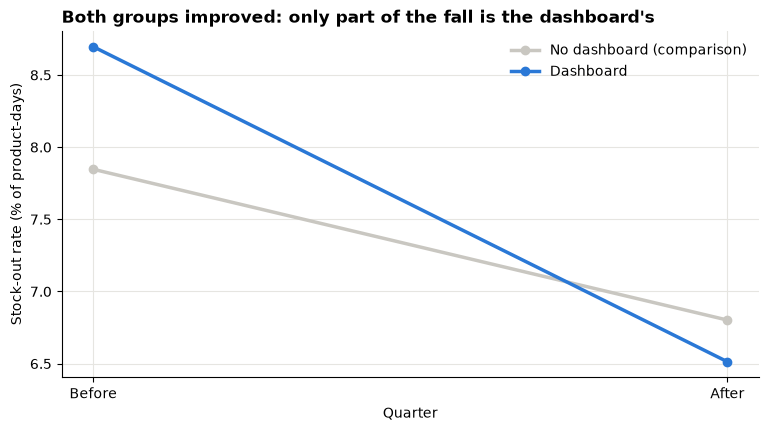

In [5]:
fig, ax = plt.subplots()
for label, colour in [("No dashboard (comparison)", GREY), ("Dashboard", BLUE)]:
    ax.plot(["Before", "After"], means.loc[label, ["before", "after"]], marker="o", linewidth=2.5,
            color=colour, label=label)
ax.set_title("Both groups improved: only part of the fall is the dashboard's")
ax.set_ylabel("Stock-out rate (% of product-days)")
ax.set_xlabel("Quarter")
ax.legend(frameon=False)
plt.show()

Read the output above. The before-and-after number mixes two things: the supplier change, which helped every store, and the dashboard. Subtracting the comparison stores' change (a **difference-in-differences**) separates them. The dashboard did help, but by less than the regional manager reported.

Two further cautions for any impact claim:

1. **Who chose the pilot stores?** If enthusiastic managers volunteered, their stores might have improved anyway. Choosing the pilot stores at random removes this doubt.
2. **What else moved?** A KPI that improves while another worsens (fresh food thrown away, for example) is not a clear win. Always check a **counter-metric**.

> **Check your understanding**
>
> For case B (the hospital), name one comparison you would want before accepting "overtime fell by a fifth", and one counter-metric that must not get worse.

---

## Part 5: Ethics: privacy, bias, transparency, misuse of metrics

BI multiplies the reach of a decision: one dashboard, model or KPI can affect thousands of customers, employees or suppliers. Four risks come up again and again.

| Risk | What goes wrong | First defence |
|---|---|---|
| **Privacy** | Personal data used beyond its purpose, kept too long, or re-identified | Collect the minimum; state the purpose; aggregate; restrict access |
| **Bias** | A model or KPI treats groups unfairly, often by learning from unfair past decisions | Check results **by group**; question proxies; involve the people affected |
| **Transparency** | Nobody can explain how a score or decision was made | Document data, method and limits; allow people to challenge decisions |
| **Misuse of metrics** | People hit the target in ways that defeat its purpose | Pair every target with counter-metrics; review behaviour, not only numbers |

### 5.1 Privacy

Privacy law in many countries rests on similar principles: a **lawful purpose**, **consent** where needed, **data minimisation** (collect only what the purpose needs), **security**, limited **retention**, and rights for the people the data describe. China's Personal Information Protection Law (PIPL, in force since 1 November 2021) and the European Union's General Data Protection Regulation (GDPR, 2018) both follow this pattern, and both contain rules on automated decision-making.

Removing names is **not** enough. A combination of ordinary attributes can single out one person. Latanya Sweeney (2000) estimated that about 87% of the US population could be uniquely identified by just ZIP code, sex and date of birth. In 2008, Narayanan and Shmatikov showed that some "anonymous" Netflix users could be re-identified by matching their film ratings with public reviews.

The tips data contain no names. But suppose an outsider knows a few facts about one dinner: the payer's sex, whether the party smoked, the day, the meal and the party size. How many bills are the **only** bill with their combination? Those bills could be linked to a person.

In [6]:
def unique_share(data, columns):
    """Share of rows whose combination of `columns` appears only once in the data."""
    group_size = data.groupby(columns)[columns[0]].transform("size")
    return (group_size == 1).mean(), int(group_size.min())


detailed = ["sex", "smoker", "day", "time", "size"]
share, smallest = unique_share(tips, detailed)
print(f"Quasi-identifiers {detailed}")
print(f"  bills that are unique on these columns: {share:.1%}  (smallest group: {smallest} bill)")

# Generalise: drop the payer's sex and group party sizes into bands
coarse = tips.assign(party=np.where(tips["size"] <= 2, "1-2 diners", "3+ diners"))
generalised = ["smoker", "day", "time", "party"]
share_g, smallest_g = unique_share(coarse, generalised)
print(f"\nQuasi-identifiers {generalised}")
print(f"  bills that are unique on these columns: {share_g:.1%}  (smallest group: {smallest_g} bill(s))")

Quasi-identifiers ['sex', 'smoker', 'day', 'time', 'size']
  bills that are unique on these columns: 9.8%  (smallest group: 1 bill)

Quasi-identifiers ['smoker', 'day', 'time', 'party']
  bills that are unique on these columns: 1.2%  (smallest group: 1 bill(s))


Read the output above. With five ordinary columns, some bills are unique, so someone who knows those facts about a dinner could find that bill and its tip. Dropping one column and grouping another reduces the risk. The idea behind **k-anonymity** is to make every combination appear at least *k* times (for example *k* = 5), so that no row can be singled out. Generalising always loses some detail: privacy and analytical value must be balanced, deliberately.

> **Check your understanding**
>
> A delivery app wants to publish a dashboard of "orders by building and hour" for city planners. Name two privacy risks and two ways to reduce them.

### 5.2 Bias

Bias can enter at every layer of the architecture:

| Source | Example |
|---|---|
| **Sampling** | Online reviews come mostly from very happy or very angry customers |
| **Historical** | A model learns from past decisions that were themselves unfair |
| **Measurement** | "Performance" measured by hours online favours staff without caring duties |
| **Proxy** | A neutral-looking column (district, school, first name) stands in for a protected group |

In 2018 Reuters reported that Amazon had abandoned an experimental recruiting tool after finding that it downgraded CVs containing the word "women's"; it had learned from ten years of CVs submitted mostly by men. Amazon said the tool was never used on its own to evaluate candidates.

The next demonstration shows how a proxy carries bias even when the group column is **removed**. The data are **synthetic**: 4,000 past job applicants with a skill score, a home district and a group label (A or B). Skill is distributed identically in both groups, but the past hiring decisions were biased against group B, and group B applicants mostly live in district 1. We train a screening model **without** the group column, as many companies would, and use it to shortlist the top 30% of applicants.

> **Predict, then reveal**
>
> The model never sees the group. Will the two groups be shortlisted at about the same rate?

In [7]:
rng = np.random.default_rng(seed=11)
n = 4_000
group = rng.choice(["A", "B"], n)
district = np.where(group == "A", rng.choice([0, 1], n, p=[0.8, 0.2]), rng.choice([0, 1], n, p=[0.25, 0.75]))
skill = rng.normal(0, 1, n)                             # same distribution in both groups
past_score = -0.5 + 1.2 * skill - 1.0 * (group == "B")  # past decisions penalised group B
hired_before = rng.uniform(size=n) < 1 / (1 + np.exp(-past_score))

# The new screening model: trained on past hiring, WITHOUT the group column
X = pd.DataFrame({"skill": skill, "district": district})
model = LogisticRegression().fit(X, hired_before)
score = model.predict_proba(X)[:, 1]
shortlisted = score >= np.quantile(score, 0.70)         # top 30% of scores

print("Model coefficients (the model never saw the group):")
print(f"  skill:    {model.coef_[0][0]:+.2f}")
print(f"  district: {model.coef_[0][1]:+.2f}")

rates = pd.Series(shortlisted).groupby(group).mean()
print("\nShare of each group shortlisted:")
for g, r in rates.items():
    print(f"  group {g}: {r:.1%}")
print(f"\nRatio of the lower rate to the higher rate: {rates.min() / rates.max():.2f}")

Model coefficients (the model never saw the group):
  skill:    +1.20
  district: -0.47

Share of each group shortlisted:
  group A: 34.4%
  group B: 25.8%

Ratio of the lower rate to the higher rate: 0.75


Read the output above. The model learned a **negative weight on district**, because district carries the information about group that the past decisions penalised. Group B is shortlisted less often even though skill is the same in both groups.

The **four-fifths rule**, used by US employment regulators as a rough screen, flags a selection process when one group's selection rate is below 80% of the highest group's rate. It is a warning light, not a verdict: the next step is to investigate why.

What helps:

1. **Measure by group.** You cannot detect this bias without the group column, so "we deleted the sensitive column" is not a defence. Keep it, securely, for auditing.
2. **Question every proxy.** Does district predict job performance, or only past prejudice?
3. **Question the target.** "Hired before" measures past decisions, not ability.
4. **Keep a human review** for decisions that matter to people, and let them challenge the result.

### 5.3 Transparency

| Practice | Why it matters |
|---|---|
| Document **data sources**, filters and definitions on the dashboard (a scope note) | Users know what the number covers |
| Explain the **method** in plain language and state its **limits** and error | Users do not over-trust a forecast |
| Show **uncertainty** (ranges, confidence bounds, probability of a loss) | A single number looks more certain than it is |
| Keep a record of **who changed** a model or KPI, and when | Mistakes can be traced and corrected |
| Tell people when an **automated decision** affects them, and how to contest it | Fairness and, in many places, the law |

### 5.4 Misuse of metrics

**Goodhart's law**, in Marilyn Strathern's (1997) wording: *"When a measure becomes a target, it ceases to be a good measure."* People are inventive: if pay depends on one number, the number will move, whether or not the real goal does.

A real example: in 2016 US regulators fined Wells Fargo after employees, under intense sales targets, opened about two million deposit and credit-card accounts that customers had not authorised (later estimates rose to about 3.5 million). The KPI, "accounts opened", rose; trust, customers and eventually the bank's reputation suffered.

The demonstration below is **synthetic**. A bank tracks new accounts opened per month across its branches. In month 13 it introduces a bonus for new accounts. It also records how many new accounts are still **active** (used at least once) 90 days later: the counter-metric.

                          new accounts active after 90 days activation rate
before (months 1-12)               996                  846             85%
with bonus (months 13-24)        1,441                  873             61%


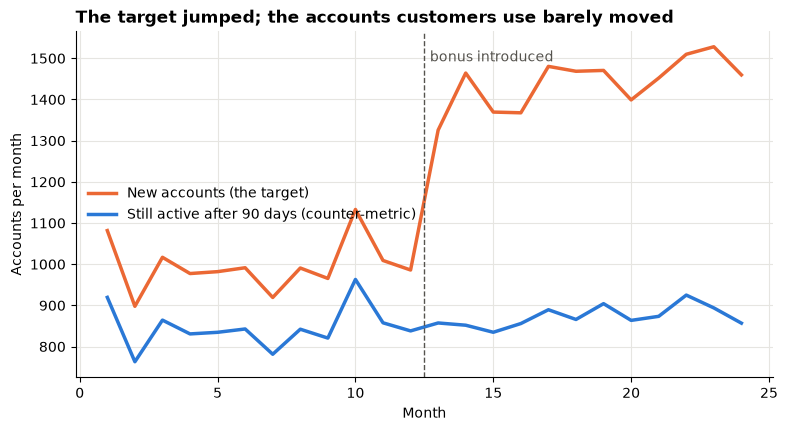

In [8]:
rng = np.random.default_rng(seed=3)
months = np.arange(1, 25)
target_on = months >= 13
genuine = rng.normal(1_000, 40, len(months))                        # accounts customers really wanted
pushed = np.where(target_on, rng.normal(450, 40, len(months)), 0)  # accounts opened to hit the target
accounts = pd.DataFrame({
    "month": months,
    "new accounts": genuine + pushed,
    "active after 90 days": genuine * 0.85 + pushed * 0.05,
})
accounts["activation rate"] = accounts["active after 90 days"] / accounts["new accounts"]

summary = accounts.groupby(np.where(target_on, "with bonus (months 13-24)", "before (months 1-12)"))[
    ["new accounts", "active after 90 days", "activation rate"]].mean()
print(summary.to_string(formatters={"new accounts": "{:,.0f}".format,
                                    "active after 90 days": "{:,.0f}".format,
                                    "activation rate": "{:.0%}".format}))

fig, ax = plt.subplots()
ax.plot(accounts["month"], accounts["new accounts"], color=ORANGE, linewidth=2.5, label="New accounts (the target)")
ax.plot(accounts["month"], accounts["active after 90 days"], color=BLUE, linewidth=2.5,
        label="Still active after 90 days (counter-metric)")
ax.axvline(12.5, color=INK, linestyle="--", linewidth=1)
ax.text(12.7, ax.get_ylim()[1] * 0.97, "bonus introduced", color=INK, va="top")
ax.set_title("The target jumped; the accounts customers use barely moved")
ax.set_xlabel("Month")
ax.set_ylabel("Accounts per month")
ax.legend(frameon=False, loc="center left")
plt.show()

Read the table and chart above: the target jumped, the counter-metric barely moved, and the activation rate fell. A dashboard that showed only "new accounts" would have reported success.

Defences against metric misuse:

| Defence | Example |
|---|---|
| **Pair** each target with a counter-metric | New accounts **and** activation after 90 days; calls handled **and** problems solved first time |
| Prefer **outcomes** to activity counts | Customers retained, not calls made |
| Watch for **sudden jumps** and audit a sample | A branch whose numbers jump in one month |
| Avoid tying large rewards to one number | Balanced scorecards, judgement, team goals |
| Ask the people who do the work | They know first how a KPI can be gamed |

> **Check your understanding**
>
> A delivery company sets a KPI "average delivery time under 30 minutes" and rewards drivers for it. Describe one way the KPI could be hit while customers or the public are harmed, and one counter-metric that would reveal it.

---

## Part 6: Societal context: putting ethics into the numbers

Business decisions affect people outside the company: workers in the supply chain, neighbours of a factory, the environment, future customers. A useful set of questions before any BI-supported decision:

| Question | Example |
|---|---|
| **Who benefits, and who bears the cost or risk?** | Cheaper batteries benefit shareholders; the cost falls on miners' working conditions |
| **Is it legal everywhere it applies, and is it likely to stay legal?** | Supply-chain due-diligence and forced-labour import rules are spreading |
| **Would we be comfortable if it were published?** | The "front page" test |
| **Can it be reversed?** | Lost trust and health effects are hard to undo |
| **What does the model leave out?** | Fines, boycotts, staff turnover, reputation: real, but rarely in the spreadsheet |

Ethics should not be one sentence at the end of a report. A strong analysis **prices what it can**, **names what it cannot**, and lets the decision-maker weigh both.

### Worked example: EcoDrive Motors' ethical premium

This afternoon's labs follow **EcoDrive Motors**, a **fictional** car maker launching an affordable electric vehicle (EV). Its plan: 15,000 vehicles a year, sold at 35,000 US dollars, with a base manufacturing cost of 28,000 per vehicle and fixed overheads of 50 million. Batteries can come from a cheaper supplier with known severe labour violations, or from an ethically certified supplier for an extra **500 dollars per vehicle**.

How big is that premium in profit terms, and how many extra cars (or how much avoided loss) would justify it?

In [9]:
demand, price, base_cost, premium, overhead = 15_000, 35_000, 28_000, 500, 50_000_000

profit_cheap = demand * (price - base_cost) - overhead
profit_ethical = demand * (price - base_cost - premium) - overhead
gap = profit_cheap - profit_ethical
margin_ethical = price - base_cost - premium      # contribution per vehicle with the ethical supplier

print(f"Net profit, cheaper supplier:      {profit_cheap:>14,.0f} USD")
print(f"Net profit, certified supplier:    {profit_ethical:>14,.0f} USD")
print(f"Cost of the ethical choice:        {gap:>14,.0f} USD ({gap / profit_cheap:.1%} of profit)")
print(f"Extra vehicles needed to cover it: {gap / margin_ethical:>14,.0f} "
      f"({gap / margin_ethical / demand:.1%} more demand)")

Net profit, cheaper supplier:          55,000,000 USD
Net profit, certified supplier:        47,500,000 USD
Cost of the ethical choice:             7,500,000 USD (13.6% of profit)
Extra vehicles needed to cover it:          1,154 (7.7% more demand)


The output above turns a vague debate into a concrete question for the board: *"Is it plausible that responsible sourcing protects or wins this many sales, or avoids losses of this size from fines, boycotts, import bans or lost contracts?"* The analysis does not answer the moral question, but it shows its price, and it shows that the price is a modest share of profit rather than the difference between profit and loss.

Lab 7 adds a second uncertainty: battery costs have been rising. The bundled workbook `data/ecodrive_battery_costs.xlsx` holds the fictional quarterly history you will forecast in Excel this afternoon.

 Period  Battery Cost per EV ($) Quarter
      1                     7500 Q1-2023
      2                     7650 Q2-2023
      3                     7900 Q3-2023
      4                     8100 Q4-2023
      5                     8000 Q1-2024
      6                     8350 Q2-2024
      7                     8600 Q3-2024
      8                     8900 Q4-2024
      9                     8800 Q1-2025
     10                     9200 Q2-2025
     11                     9550 Q3-2025


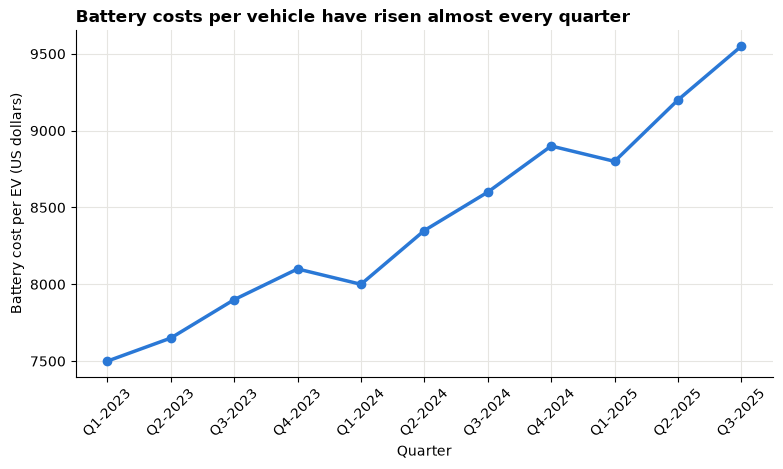

In [10]:
battery = pd.read_excel("data/ecodrive_battery_costs.xlsx", usecols="A:C")
print(battery.to_string(index=False))

fig, ax = plt.subplots()
ax.plot(battery["Quarter"], battery["Battery Cost per EV ($)"], marker="o", color=BLUE, linewidth=2.5)
ax.set_title("Battery costs per vehicle have risen almost every quarter")
ax.set_xlabel("Quarter")
ax.set_ylabel("Battery cost per EV (US dollars)")
ax.tick_params(axis="x", rotation=45)
plt.show()

> **Check your understanding**
>
> A board member says: "The ethical premium costs us millions; the data say drop it." Write two sentences in reply that use the numbers above **and** name one risk the spreadsheet does not contain.

---

## Part 7: Assignment 3 briefing

[Assignment 3: Spreadsheet simulation and decision model](D6_assignment3_simulation_decision_model.md) is **6%** of the course grade (CLO 3, 4 and 5) and is due **Sunday 22 November, 23:59 China Standard Time** on **GAP (Moodle)**.

| | |
|---|---|
| **Case** | SmartHome Tech (fictional) launches an AI-powered thermostat. Baseline demand is about 1,000 units a month with random swings; each unit earns a fixed profit margin. Choose between a **Standard** and an **Aggressive** marketing strategy |
| **Excel** | Simulate 12 months of demand with `RANDBETWEEN`, compute each strategy's monthly profit, then **freeze** the random numbers with Paste Special → Values |
| **Tableau** | Connect to your workbook and draw both strategies' monthly profit as two lines |
| **Report** | A short executive report with your Tableau chart, answering two questions: which strategy is better and more consistent, and why simulating volatility is safer than planning on a fixed number |
| **Submit** | Your locked Excel file and one PDF report |

How it connects to today:

1. Parts 1–2 of the assignment are the same skills as **Lab 6** (random inputs, a profit model, a summary).
2. The report is a **managerial report**: lead with the recommendation, quote numbers with units, state the limits (Part 5 and Day 5's reporting rules).
3. Freezing the numbers is essential: Tableau reads the values saved in the file, and your report must describe the same simulation your chart shows.

> **Common mistakes to avoid**
>
> - Forgetting Paste Special → Values, so the numbers in the report no longer match the workbook.
> - Leaving `Month` as a measure in Tableau, which sums all months into one point.
> - Answering "Aggressive is better" without saying **how much** better, **how much more variable**, and **why** (look at the formulas, not only the chart).

---

## Summary

| Idea | One-line takeaway |
|---|---|
| Business intelligence | People, process and tools that turn data into repeated, trusted decisions |
| BI strategy | Goals, people, process, data and governance, technology, value and adoption |
| Maturity | From ad hoc spreadsheets to governed, predictive, prescriptive BI; levels are rarely skipped |
| Architecture | Sources → integration → storage → semantic layer → analysis → decisions |
| Tools | Excel for models and what-if, Python for repeatable analysis, Tableau for dashboards |
| Metric contract | One written definition per KPI; "mean of ratios" and "ratio of totals" differ |
| Judging impact | Compare with a comparison group; check counter-metrics; ask who chose the pilot |
| Privacy | Removing names is not anonymisation; minimise, aggregate, generalise |
| Bias | Deleting the group column does not remove bias; measure outcomes by group |
| Transparency | Document data, method, limits and uncertainty; let people contest decisions |
| Misuse of metrics | When a measure becomes a target, pair it with a counter-metric |
| Societal context | Price what you can, name what you cannot, and let the board weigh both |

---

## Closing quiz

1. Give one difference between a one-off analysis and business intelligence.
2. Name the six elements of a BI strategy, and the one that most often explains "many dashboards, no change in decisions".
3. In the BI architecture, in which layer should the definition of "active customer" live, and why?
4. One dashboard reports the tip rate as the average of each bill's rate; another as total tips ÷ total bills. Which gives each **dollar** equal weight?
5. A pilot store's stock-outs fell by 2 points; stores without the pilot fell by 1.5 points. What is the best estimate of the pilot's effect, and what would make you trust it more?
6. Why can a dataset with no names still identify people? Give one remedy.
7. A screening model never sees applicants' gender, yet selects women at 60% of the rate of men. Give two possible explanations and one next step.
8. State Goodhart's law and give a counter-metric for a call centre measured on "calls handled per hour".

---

## This afternoon

**Lab 1 of 2:** [Applied Lab 6: Advanced spreadsheet simulation](D6_lab_lab6_spreadsheet_simulation.md) (graded, 2%). In Excel you build EcoDrive Motors' profit model, a two-way Data Table, a 50-trial risk simulation, and answer questions on risk and the ethical premium.

**Lab 2 of 2:** [Applied Lab 7: BI case study implementation](D6_lab_lab7_bi_case_study.md) (graded, 2%). You forecast battery costs with Excel's Forecast Sheet, compare three sourcing strategies on a case-study dashboard, and write a short managerial report.

Both labs are due **today, 23:59 China Standard Time**, on GAP (Moodle).

**Tomorrow:** course review and the final exam.